# How Diversified is an S&P 500 ETF?
## Technology Concentration and Revenue Growth in the S&P 500 at the End of 2024

**Author:** Tobias Frei · **Course:** AI Mastery Capstone, Project 2 · **Date:** 2026-11-21

**Dataset:** sp500_companies.csv from S&P 500 Stocks by Larxel, Version 1023, Kaggle, CC0 license
(https://www.kaggle.com/datasets/andrewmvd/sp-500-stocks). 

The file describes the companies in the S&P 500 index on 2024-12-20, one row per listed ticker, with sector, market value, revenue growth and further company data. The Kaggle page does not name the source, but the columns match the data of Yahoo Finance.
It is a snapshot, so every value refers to the state of the companies at the end of 2024.

"Daily updated" means that the dataset was rebuilt every day until December 2024, not that this file contains daily data. The file has no date column. I took 2024-12-20 as the date of the snapshot because it is the last trading day in
the price files of the same version (Version 1023, published 2024-12-23).


Note: Finding the right dataset for this project was a challenge I also investigated several different Kaggle datasets, but some where to broad and deep so I decided to go with this one, since it ticked all the requirements and is suitable to answer my research questions.

### Motivation
An S&P 500 ETF is often called a safe long-term investment, because you own 500 companies. But the index is weighted by market value, so a few big technology companies get a large part of the money. In this notebook I first look at how concentrated the index is. Then I test if tech companies really grow their revenue faster than the rest, which would be one reason for their big weight. 
Disclaimer: This is not investment advice.

### Analysis Plan
I created this plan prior to the comparison of groups, so the results dont influence my hypothesis. This follows the advice from (Lusa et al., 2024) to conduct data analysis initially.

### Research Flow

- Descriptive Statistics: What share of the total market value do the sectors and the 10 biggest companies posses, comparing it to their share of all the companies.
- Test Questions: Analysis the question if the mean revenue growth of tech companies differ from the mean of all other companies.
- Outcome: Will be calculated in Revenuegrowth in %
- Groups: Will filter the companies: Technology vs. all other sectors, one row per ticker.
- Hypotheses: H0: μ_Tech = μ_Other_Sectors: They are the same: H1: μ_Tech ≠ μ_Other_Sectors (two-sided) They are significantly different testing both lower and higher contribution.
- Significance Level: I am using an alpha of 0.05
- Testing: I will be using a t-test
- Robustness Checking: I will use the bootstrap method with 95% intervals for the differences in means and in the medians with a t-test to investigate further.

All the decisions I make along the way will be documented.

### Table of Content
1. Setup
2. Ingestion & Dataset Description
3. Data Investigation
5. Data Cleaning
6. Descriptive Statistics
7. Visualization
8. Hypothesis Testing
9. Summary




---

## 1. Setup

In [1]:
# Libraries Import
import sys
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, PercentFormatter
from scipy import stats


In [2]:
# Setting up configurations 
DATA = "sp500_companies.csv"
ALPHA = 0.05
SEED = 42

# Colors for the figures: one fixed color per group, everything else in calm greys.
# Blue and orange pass the color checks for lightness, saturation, color blindness and contrast.
COLOR_TECH = "#2a78d6"            # Technology
COLOR_OTHER = "#eb6834"           # all other sectors
COLOR_NEUTRAL = "#8f8d86"         # all companies together, or no group
COLOR_NEUTRAL_LIGHT = "#d6d4cd"   # background values (share of companies, outer 5 % of the bootstrap)
GROUP_COLORS = {"Technology": COLOR_TECH, "Other sectors": COLOR_OTHER}

# Colors for background, text, grid and axes
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"

# Adding seed for reproducibility
np.random.seed(SEED)

# Setting up the theme for all plots: light background, thin grey grid, no top and right frame
sns.set_theme(
    style="white",
    rc={
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 110,
        "font.family": "sans-serif",
        "font.sans-serif": ["Segoe UI", "Arial", "DejaVu Sans"],
        "text.color": INK,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.labelcolor": INK_SECONDARY,
        "axes.labelsize": 10,
        "axes.titlesize": 13,
        "axes.titleweight": "semibold",
        "axes.titlecolor": INK,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.axisbelow": True,
        "xtick.color": AXIS,
        "ytick.color": AXIS,
        "xtick.labelcolor": INK_SECONDARY,
        "ytick.labelcolor": INK_SECONDARY,
        "xtick.labelsize": 9.5,
        "ytick.labelsize": 9.5,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "grid.linestyle": "-",
        "legend.frameon": False,
        "legend.fontsize": 9.5,
    },
)

# Figures in double resolution: same size on screen, but sharp lines and text,
# and bars with only one company do not look lighter than the others
%config InlineBackend.figure_formats = ["retina"]

In [3]:
# Two small helpers so that all four figures look the same

def add_title(ax: plt.Axes, title: str, subtitle: str) -> None:
    """Writes a left-aligned figure title and a one-line subtitle above a plot.

    The title carries the figure number and what is plotted, for example
    "Figure 1. Revenue growth of S&P 500 companies". The subtitle sits between
    the title and the plot in a lighter grey and explains how to read the figure
    (sample size, what a line or a dot stands for), so the reader does not need
    a separate legend for these explanations.

    The subtitle is positioned in points above the top edge of the plot area,
    not in data or axes units. Because of this it keeps the same distance to
    the plot for every figure size, and the title padding of 24 points always
    leaves room for exactly one subtitle line.

    Args:
        ax: The matplotlib axes that receives the title. The title is aligned
            with the left edge of this axes.
        title: The main title, written in the bold title style of the theme.
        subtitle: One short line of explanation, written in the secondary text
            color at a smaller font size. Longer text would run past the right
            edge, so keep it to one sentence.

    Returns:
        None. The axes is changed in place.
    """
    ax.set_title(title, loc="left", pad=24)
    ax.annotate(
        subtitle,
        xy=(0, 1),
        xycoords="axes fraction",
        xytext=(0, 7),
        textcoords="offset points",
        ha="left",
        va="bottom",
        fontsize=9.5,
        color=INK_SECONDARY,
    )


def style_axes(ax: plt.Axes, grid_axis: str) -> None:
    """Gives a plot the calm frame used in this notebook: a thin grid on one axis only, no tick marks.

    A grid on both axes adds lines that carry no information. For a histogram
    the reader compares bar heights, so only horizontal grid lines help. For
    horizontal bars or box plots the reader compares lengths along the x-axis,
    so only vertical grid lines help. The tick marks are removed because the
    grid lines already show where each tick label belongs. Grid color, width
    and the solid line style come from the theme set in the setup cell.

    Args:
        ax: The matplotlib axes to style.
        grid_axis: "x" for vertical grid lines, "y" for horizontal grid lines.
            The value is passed on to matplotlib unchanged, so "both" also works.

    Returns:
        None. The axes is changed in place.
    """
    ax.grid(axis=grid_axis)
    ax.tick_params(length=0)

In [4]:
# Checking versions to avoid conflicts
print(f"Python {sys.version.split()[0]}, pandas {pd.__version__}, NumPy {np.__version__}, " f"SciPy {scipy.__version__}, Matplotlib {matplotlib.__version__}, seaborn {sns.__version__}")

Python 3.12.7, pandas 3.1.1, NumPy 2.5.5, SciPy 1.18.1, Matplotlib 3.11.2, seaborn 0.13.2


---

## 2. Ingestion & Dataset Description

In [5]:
# Loading the raw data
df_raw = pd.read_csv(DATA)
df_raw.head()

,Exchange,Symbol,Shortname,Longname,Sector,Industry,Currentprice,Marketcap,Ebitda,Revenuegrowth,City,State,Country,Fulltimeemployees,Longbusinesssummary,Weight
0,NMS,AAPL,Apple Inc.,Apple Inc.,Technology,Consumer Electronics,254.49,3846819807232,1.346610e+11,0.061,Cupertino,CA,United States,164000.0,"Apple Inc. designs, manufactures, and markets ...",0.069209
1,NMS,NVDA,NVIDIA Corporation,NVIDIA Corporation,Technology,Semiconductors,134.70,3298803056640,6.118400e+10,1.224,Santa Clara,CA,United States,29600.0,NVIDIA Corporation provides graphics and compu...,0.059350
2,NMS,MSFT,Microsoft Corporation,Microsoft Corporation,Technology,Software - Infrastructure,436.60,3246068596736,1.365520e+11,0.160,Redmond,WA,United States,228000.0,Microsoft Corporation develops and supports so...,0.058401
3,NMS,AMZN,"Amazon.com, Inc.","Amazon.com, Inc.",Consumer Cyclical,Internet Retail,224.92,2365033807872,1.115830e+11,0.110,Seattle,WA,United States,1551000.0,"Amazon.com, Inc. engages in the retail sale of...",0.042550
4,NMS,GOOGL,Alphabet Inc.,Alphabet Inc.,Communication Services,Internet Content & Information,191.41,2351625142272,1.234700e+11,0.151,Mountain View,CA,United States,181269.0,Alphabet Inc. offers various products and plat...,0.042309


In [6]:
df_raw.describe()

,Currentprice,Marketcap,Ebitda,Revenuegrowth,Fulltimeemployees,Weight
count,502.000000,5.020000e+02,4.730000e+02,499.000000,4.930000e+02,502.000000
mean,217.893685,1.107222e+11,7.045286e+09,0.070541,5.782761e+04,0.001992
std,489.205027,3.440074e+11,1.624213e+10,0.180247,1.395988e+05,0.006189
min,9.400000,4.664099e+09,-3.991000e+09,-0.602000,2.800000e+01,0.000084
25%,68.547500,1.933417e+10,1.625000e+09,0.002000,1.020000e+04,0.000348
50%,118.365000,3.706396e+10,2.952748e+09,0.051000,2.169000e+04,0.000667
75%,227.667500,7.830565e+10,6.020000e+09,0.109000,5.510000e+04,0.001409
max,8276.780000,3.846820e+12,1.495470e+11,1.632000,2.100000e+06,0.069209


In [7]:
df_raw.shape

(502, 16)

In [8]:
df_raw.dtypes

Exchange                   str
Symbol                     str
Shortname                  str
Longname                   str
Sector                     str
Industry                   str
Currentprice           float64
Marketcap                int64
Ebitda                 float64
Revenuegrowth          float64
City                       str
State                      str
Country                    str
Fulltimeemployees      float64
Longbusinesssummary        str
Weight                 float64
dtype: object

#### Observation
Text columns are stored as str, numbers as float64 or int64. pandas 3 uses its own data type for text, and not object.

In [9]:
# Why is Fulltimeemployees a float and not an integer?
employees = df_raw["Fulltimeemployees"]
print("Data type:", employees.dtype)


Data type: float64


In [10]:
employees.head()

0     164000.0
1      29600.0
2     228000.0
3    1551000.0
4     181269.0
Name: Fulltimeemployees, dtype: float64

In [11]:
print("Missing values:", employees.isna().sum())

# This explains why Fulltimeemployees is a float and not an integer: there are missing values.

Missing values: 9


In [12]:
# Companies with missing Fulltimeemployees values
df_raw.loc[employees.isna(), ["Symbol", "Shortname", "Sector"]]


,Symbol,Shortname,Sector
13,V,Visa Inc.,Financial Services
97,SBUX,Starbucks Corporation,Consumer Cyclical
206,DHI,"D.R. Horton, Inc.",Consumer Cyclical
257,RMD,ResMed Inc.,Healthcare
274,RJF,"Raymond James Financial, Inc.",Financial Services
384,SMCI,"Super Micro Computer, Inc.",Technology
430,FFIV,"F5, Inc.",Technology
464,SOLV,Solventum Corporation,Healthcare
501,AMTM,"Amentum Holdings, Inc.",Industrials


### Data Types Explanation
502 rows and 16 columns. Text columns are strings, numbers are float64 or int64. The column Fulltimeemployees is a float only because it has missing values. The rest does not show any anomalies compared to other datasets.


**What the columns mean** (from the Kaggle page)

| Column | Meaning |
|---|---|
| Exchange | Stock exchange (NYQ = New York Stock Exchange, NMS  = Nasdaq) where the stocks are negociated |
| Symbol | Stock Symbol (ticker) |
| Shortname, Longname | Company name |
| Sector, Industry | Sector and industry where the company operates |
| Currentprice | Share price in USD |
| Marketcap | market value of the company in USD |
| Ebitda | Earnings before interest, taxes, depreciation and amortization |
| Revenuegrowth | Revenue growth, compared to the same quarter 1 year before (cross-checked with quarterly reports of large companies) |
| City, State, Country | City, State and Country of the headquater |
| Fulltimeemployees | Number of full-time employees |
| Longbusinesssummary | Short description of the business |
| Weight | Percentage of participation on the S&P index (marketcap %) |

The file has no date column. I took 2024-12-20 as the date of the snapshot because it is the last trading day in the price files of the same version (Version 1023, published 2024-12-23).

---

## 3. Data Investigation
Before I elaborate on my research questions, I check missing values, duplicates, strange values categories.

### 3.1 Missing Values

In [13]:
# Building a reusable function for profile_missing, this function will be reused after cleaning and imputing the dataset.
def profile_missing(frame: pd.DataFrame) -> pd.DataFrame:
    """Returns the number and percent of missing values for every column that has gaps."""
    counts = frame.isna().sum()
    counts = counts[counts > 0].sort_values(ascending=False)
    return pd.DataFrame({"missing": counts, "percent": (counts / len(frame) * 100).round(1)})

In [14]:
profile_missing(df_raw)

,missing,percent
Ebitda,29,5.8
State,20,4.0
Fulltimeemployees,9,1.8
Revenuegrowth,3,0.6


In [15]:
# Rows without Ebitda, counted by sector
missing_ebitda = df_raw[df_raw["Ebitda"].isna()]
missing_ebitda["Sector"].value_counts()

Sector
Financial Services    29
Name: count, dtype: int64

In [16]:
# Companies without revenue growth
missing_growth = df_raw[df_raw["Revenuegrowth"].isna()]
missing_growth[["Symbol", "Shortname", "Sector"]]


,Symbol,Shortname,Sector
55,VZ,Verizon Communications Inc.,Communication Services
109,AMT,American Tower Corporation (REI,Real Estate
359,WDC,Western Digital Corporation,Technology


In [17]:
# Rows without State, counted by country
missing_state = df_raw[df_raw["State"].isna()]
missing_state["Country"].value_counts()


Country
Ireland           10
United Kingdom     3
Switzerland        3
Bermuda            2
Netherlands        1
Singapore          1
Name: count, dtype: int64

In [18]:
# Companies without an employee number
missing_employees = df_raw[df_raw["Fulltimeemployees"].isna()]
missing_employees[["Symbol", "Shortname", "Sector"]]


,Symbol,Shortname,Sector
13,V,Visa Inc.,Financial Services
97,SBUX,Starbucks Corporation,Consumer Cyclical
206,DHI,"D.R. Horton, Inc.",Consumer Cyclical
257,RMD,ResMed Inc.,Healthcare
274,RJF,"Raymond James Financial, Inc.",Financial Services
384,SMCI,"Super Micro Computer, Inc.",Technology
430,FFIV,"F5, Inc.",Technology
464,SOLV,Solventum Corporation,Healthcare
501,AMTM,"Amentum Holdings, Inc.",Industrials


In [19]:
missing_employees["Sector"].value_counts()

Sector
Financial Services    2
Consumer Cyclical     2
Healthcare            2
Technology            2
Industrials           1
Name: count, dtype: int64

#### Observation

- Ebitda (29 missing): all of them are in Financial Services. I researched and banks and insurers do not report this number, so the gap is not random. I do not use this column.
- State (20 missing): all of these companies have their headquarters outside the US, most of them in Ireland. They have no US state, so this is expected.
- Fulltimeemployees: (9 missing): the gaps are spread over five sectors, so there is no pattern. The column is only a float because of these gaps. I do not use it in the analysis.
- Revenuegrowth: (3 missing): Verizon, American Tower and Western Digital. This is my outcome, so I drop these 3 companies from the test. 3 of 502 rows (0.6 %) is too few to change the result, but it should be documented (Lusa et al., 2024).


### 3.2 Dublicates


In [20]:
print("Duplicate rows:", df_raw.duplicated().sum())
print("Duplicate symbols:", df_raw["Symbol"].duplicated().sum())

Duplicate rows: 0
Duplicate symbols: 0


In [21]:
# Also checking for shared classes
share_classes = df_raw[df_raw["Longname"].duplicated(keep=False)]
share_classes[["Symbol", "Longname", "Sector", "Marketcap", "Revenuegrowth"]]

,Symbol,Longname,Sector,Marketcap,Revenuegrowth
4,GOOGL,Alphabet Inc.,Communication Services,2351625142272,0.151
5,GOOG,Alphabet Inc.,Communication Services,2351623045120,0.151
345,FOXA,Fox Corporation,Communication Services,21946050560,0.111
346,FOX,Fox Corporation,Communication Services,21941315584,0.111
410,NWS,News Corporation,Communication Services,16374949888,0.031
411,NWSA,News Corporation,Communication Services,16357357568,0.031


#### Observations

No duplicate rows but the companies Alphabet, Fox and News Corp are in the file multiple times, because they have two types of shares (share classes). Both rows have the same sector and the same growth. Counting them twice would be wrong, we will handle this in the cleaning phase.

### 3.3 Checking if weight is marketcap in  %


In [22]:
# Calculating implied weight based on market capitalization
implied_weight = df_raw["Marketcap"] / df_raw["Marketcap"].sum()
# Cheking if the actual weight matches the implied weight for the largest companies
largest_companies = df_raw.nlargest(10, "Marketcap")
largest_companies[["Symbol", "Marketcap", "Weight"]].assign(ImpliedWeight=implied_weight[largest_companies.index])


,Symbol,Marketcap,Weight,ImpliedWeight
0,AAPL,3846819807232,0.069209,0.069209
1,NVDA,3298803056640,0.059350,0.059350
2,MSFT,3246068596736,0.058401,0.058401
3,AMZN,2365033807872,0.042550,0.042550
4,GOOGL,2351625142272,0.042309,0.042309
5,GOOG,2351623045120,0.042309,0.042309
6,META,1477457739776,0.026581,0.026581
7,TSLA,1351627833344,0.024317,0.024317
8,AVGO,1031217348608,0.018553,0.018553
9,BRK-B,978776031232,0.017609,0.017609


#### Observation
Yes Weight is just Marketcap divided by the total, so it does not add nothing new.

### 3.4 Checking target variable for plausability

I will use different checks to make sure we dont have any strange and unexplainable values in the outcome variable.

In [23]:
# Step 1: What is the lowest and the highest revenue growth?
growth = df_raw["Revenuegrowth"]
print("Lowest value:", growth.min())
print("Highest value:", growth.max())

Lowest value: -0.602
Highest value: 1.632


In [24]:
# Step 2: How many companies had less revenue than one year before?
print("Negative values:", (growth < 0).sum())

Negative values: 124


In [25]:
# Step 3: Is 0 used as a placeholder for missing data?
# Checking against missing values again and getting the exact companies
print("Missing values:", growth.isna().sum())
print("Exact zeros:", (growth == 0).sum())

Missing values: 3
Exact zeros: 0


In [26]:
# Step 4: Checking for data collection errors, by printing out the 5 largest revenue growth values for plausability
df_raw.nlargest(5, "Revenuegrowth")[["Symbol", "Shortname", "Sector", "Revenuegrowth"]]

,Symbol,Shortname,Sector,Revenuegrowth
307,SW,Smurfit WestRock plc,Consumer Cyclical,1.632
384,SMCI,"Super Micro Computer, Inc.",Technology,1.430
223,PRU,"Prudential Financial, Inc.",Financial Services,1.334
1,NVDA,NVIDIA Corporation,Technology,1.224
96,MU,"Micron Technology, Inc.",Technology,0.933


In [27]:
# Step 5: Doing the same for the lowest revenue growth values
df_raw.nsmallest(5, "Revenuegrowth")[["Symbol", "Shortname", "Sector", "Revenuegrowth"]]

,Symbol,Shortname,Sector,Revenuegrowth
403,KEY,KeyCorp,Financial Services,-0.602
287,MCHP,Microchip Technology Incorporat,Technology,-0.484
471,ALB,Albemarle Corporation,Basic Materials,-0.414
167,AFL,AFLAC Incorporated,Financial Services,-0.404
392,PFG,Principal Financial Group Inc,Financial Services,-0.345


#### Observations

- The values go from −0.602 to 1.632, no value is exactly 0, and 124 values are negative.
- I checked a few values against the quarterly reports of the companies. They match the revenue growth of one quarter compared with the same quarter one year before. So 124 companies had less revenue than one year before.

Because a few values are very high or very low, I will also check the result with the median.



### 3.5 Checking Categories

In [28]:
# Step 1: How many companies are in each sector? Is any sector too small for a group?
df_raw["Sector"].value_counts()

Sector
Technology                82
Industrials               70
Financial Services        67
Healthcare                62
Consumer Cyclical         55
Consumer Defensive        37
Utilities                 32
Real Estate               31
Communication Services    22
Energy                    22
Basic Materials           22
Name: count, dtype: int64

In [29]:
# Step 2: On which stock exchanges are the companies?
df_raw["Exchange"].value_counts()

Exchange
NYQ    348
NMS    152
BTS      1
NGM      1
Name: count, dtype: int64

In [30]:
# Step 3: In which countries are the companies located?
df_raw["Country"].value_counts()

Country
United States     481
Ireland            10
United Kingdom      3
Switzerland         3
Bermuda             2
Netherlands         1
Canada              1
Singapore           1
Name: count, dtype: int64

In [31]:
# Step 4: In which sectors are the largest companies?
df_raw.nlargest(10, "Marketcap")[["Symbol", "Shortname", "Sector"]]


,Symbol,Shortname,Sector
0,AAPL,Apple Inc.,Technology
1,NVDA,NVIDIA Corporation,Technology
2,MSFT,Microsoft Corporation,Technology
3,AMZN,"Amazon.com, Inc.",Consumer Cyclical
4,GOOGL,Alphabet Inc.,Communication Services
5,GOOG,Alphabet Inc.,Communication Services
6,META,"Meta Platforms, Inc.",Communication Services
7,TSLA,"Tesla, Inc.",Consumer Cyclical
8,AVGO,Broadcom Inc.,Technology
9,BRK-B,Berkshire Hathaway Inc. New,Financial Services


#### Observation

No sector is too small, because the smallest has 22 companies! Technology is the biggest with 82. Exchange and country are not used in the analysis.

Good to know: the sector labels in this file put Alphabet and Meta in Communication Services and Amazon in Consumer Cyclical. So "Technology" in this file is smaller than what people usually mean with "big tech"!

---

## 4. Data Cleaning
Based on the data check in Section 3 I clean the data step by step. The raw data in df_raw stay unchanged for future reference.

In [32]:
# Step 1: Keep one row per company.
# Alphabet, Fox and News Corp have two share classes (see 3.2). Both rows of a company have the same sector, the same growth and almost the same market value (the value of the whole company), so I keep the first row.

companies = df_raw.drop_duplicates(subset="Longname", keep="first").copy()
print("Rows before:", len(df_raw))
print("Companies after:", len(companies))

Rows before: 502
Companies after: 499


In [33]:
# Step 2: Which rows did I remove?
df_raw[~df_raw["Symbol"].isin(companies["Symbol"])][["Symbol", "Longname"]]

,Symbol,Longname
5,GOOG,Alphabet Inc.
346,FOX,Fox Corporation
411,NWSA,News Corporation


In [34]:
# Step 3: Check that every company is now in the data only once
companies["Longname"].is_unique

True

#### Observation

In total we end up with only 499 companies in the dataset, which is strange since the S&P500 consists of 500, so potentially there was a merger, or some other event happening.

In [35]:
# Step 4: Drop the 3 companies without revenue growth. My test will need a value for every company.
df = companies.dropna(subset=["Revenuegrowth"]).copy()
print("Companies with revenue growth:", len(df))

Companies with revenue growth: 496


In [36]:
# Step 5: Revenue growth in percent (0.05 -> 5.0) will be much easier to read in tables and figures
df["revenue_growth_pct"] = df["Revenuegrowth"] * 100
df[["Symbol", "Revenuegrowth", "revenue_growth_pct"]].head()

,Symbol,Revenuegrowth,revenue_growth_pct
0,AAPL,0.061,6.1
1,NVDA,1.224,122.4
2,MSFT,0.160,16.0
3,AMZN,0.110,11.0
4,GOOGL,0.151,15.1


In [37]:
# Step 6: Two groups for the test Technology and all other sectors
df["group"] = np.where(df["Sector"] == "Technology", "Technology", "Other sectors")
df["group"].value_counts()

group
Other sectors    415
Technology        81
Name: count, dtype: int64

### Result of the cleaning
- 502 rows --> 499 companies (one row per company): dataset: companies --> 496 companies with revenue growth: dataset: df (main dataset)
- 81 in Technology and 415 in other sectors.


---

## 5. Descriptive Statistics

### 5.1 Summary statistics
Only the two numeric columns I use: market value (in billion USD) and revenue growth (in %).

In [38]:
# Step 1: Market value in billion USD (1 billion = 1000000000), so the numbers are easier to read, and additionally round the summary statistics for better readability
companies["marketcap_bn"] = companies["Marketcap"] / 1000000000
round(companies["marketcap_bn"].describe(), 2)

count     499.00
mean      106.60
std       330.03
min         4.66
25%        19.35
50%        37.19
75%        78.07
max      3846.82
Name: marketcap_bn, dtype: float64

In [39]:
# Step 2: Skewness of the market value (0 = symmetric, positive / negative skewed)
print(round(companies["marketcap_bn"].skew(), 2))

8.16


In [40]:
# Step 3: Revenue growth in % (the column from Data Cleaning, Step 5)
round(df["revenue_growth_pct"].describe(), 2)

count    496.00
mean       7.04
std       18.07
min      -60.20
25%        0.12
50%        5.00
75%       10.90
max      163.20
Name: revenue_growth_pct, dtype: float64

In [41]:
# Step 4: Skewness of revenue growth
print(round(df["revenue_growth_pct"].skew(), 2))

3.82


#### Observation

Both columns are right-skewed (skewness 8.16 and 3.82), a few very big values seem to pull the mean higher than the median. The median market value is USD 37.19 billions (50%), the mean USD 106.60 billions. 
The typical company grew its revenue by 5.0 %, the mean is 7.0 %, and 124 of the 496 companies (25 %) had falling revenue (0.12). 
That is why I report the median and the quartiles next to the mean, like Lusa et al. (2024).

### 5.2 Companies and market values per sector
An ETF invests by market value, so a sectors share of the market value is the share of my money in it.

In [42]:
# Step 1: How many companies are in each sector? Recap from above
sector_count = companies["Sector"].value_counts()
sector_count

Sector
Technology                82
Industrials               70
Financial Services        67
Healthcare                62
Consumer Cyclical         55
Consumer Defensive        37
Utilities                 32
Real Estate               31
Energy                    22
Basic Materials           22
Communication Services    19
Name: count, dtype: int64

In [43]:
# Step 2: Share of the companies in % (companies in the sector / all 499 companies)
share_of_companies = sector_count / 499 * 100
round(share_of_companies, 2)

Sector
Technology                16.43
Industrials               14.03
Financial Services        13.43
Healthcare                12.42
Consumer Cyclical         11.02
Consumer Defensive         7.41
Utilities                  6.41
Real Estate                6.21
Energy                     4.41
Basic Materials            4.41
Communication Services     3.81
Name: count, dtype: float64

In [44]:
# Step 3: Total market value of each sector in billions
sector_value = companies.groupby("Sector")["marketcap_bn"].sum()
round(sector_value, 2)

Sector
Basic Materials             864.55
Communication Services     5414.12
Consumer Cyclical          6372.35
Consumer Defensive         3253.84
Energy                     1598.67
Financial Services         7108.16
Healthcare                 5190.43
Industrials                3764.60
Real Estate                1081.49
Technology                17287.01
Utilities                  1257.37
Name: marketcap_bn, dtype: float64

In [45]:
# Step 4: Share of the total market value in % (market value of the sector / market value of all companies)
share_of_value = sector_value / companies["marketcap_bn"].sum() * 100
round(share_of_value, 2)

Sector
Basic Materials            1.63
Communication Services    10.18
Consumer Cyclical         11.98
Consumer Defensive         6.12
Energy                     3.01
Financial Services        13.36
Healthcare                 9.76
Industrials                7.08
Real Estate                2.03
Technology                32.50
Utilities                  2.36
Name: marketcap_bn, dtype: float64

In [46]:
# Step 5 Both shares in only one table, sorted by the share of market value
# Create a table with both shares side by side
concentration = pd.DataFrame()

# Add the share of companies and share of market value to the table
concentration["share_of_companies_pct"] = share_of_companies
concentration["share_of_market_value_pct"] = share_of_value

# Sort the table by the share of market value in descending order
concentration = concentration.sort_values("share_of_market_value_pct", ascending=False)
concentration

,share_of_companies_pct,share_of_market_value_pct
Sector,,
Technology,16.432866,32.498901
Financial Services,13.426854,13.363065
Consumer Cyclical,11.022044,11.979771
Communication Services,3.807615,10.178340
Healthcare,12.424850,9.757805
Industrials,14.028056,7.077302
Consumer Defensive,7.414830,6.117088
Energy,4.408818,3.005440
Utilities,6.412826,2.363805


In [47]:
# Step 6: The 10 biggest companies by market value (in billion USD)
top10 = companies.nlargest(10, "marketcap_bn")
top10[["Symbol", "Shortname", "Sector", "marketcap_bn"]]

,Symbol,Shortname,Sector,marketcap_bn
0,AAPL,Apple Inc.,Technology,3846.819807
1,NVDA,NVIDIA Corporation,Technology,3298.803057
2,MSFT,Microsoft Corporation,Technology,3246.068597
3,AMZN,"Amazon.com, Inc.",Consumer Cyclical,2365.033808
4,GOOGL,Alphabet Inc.,Communication Services,2351.625142
6,META,"Meta Platforms, Inc.",Communication Services,1477.457740
7,TSLA,"Tesla, Inc.",Consumer Cyclical,1351.627833
8,AVGO,Broadcom Inc.,Technology,1031.217349
9,BRK-B,Berkshire Hathaway Inc. New,Financial Services,978.776031
10,WMT,Walmart Inc.,Consumer Defensive,740.999889


In [48]:
# Step 7: Share of the 10 biggest companies in the total market value
top10_share = top10["marketcap_bn"].sum() / companies["marketcap_bn"].sum() * 100
print(round(top10_share, 2))

38.89


In [49]:
# Step 8: Share of these 10 companies in the number of companies
print(round(10 / 499 * 100, 2))

2.0


#### Observation

- The index is a lot less spread than 500 companies sounds. 
- Technology is 16.4 % of the companies but they have 32.5 % of the market value, twice as much. 
- The 10 biggest companies are 2.0 % of the companies but hold 38.9 %. 
- Eight of them are tech companies (Apple, NVIDIA, Microsoft, Amazon, Alphabet, Meta, Tesla, Broadcom) even if the dataset puts four of them in other sectors. 
- This big weight would make more sense if technology companies also grow faster. That is what I will test later on!

### 5.3 Revenue growth by group

In [50]:
# DESCRIBE by group
group_summary = df.groupby("group")["revenue_growth_pct"].describe()
group_summary

,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
Other sectors,415.0,6.150602,15.881143,-60.2,-0.2,4.5,9.9,163.2
Technology,81.0,11.582716,26.287620,-48.4,2.5,7.1,16.6,143.0


#### Observation

Technology companies grow faster on average (mean 11.6 % vs. 6.2 %, 5.4 percent points more), but the medians differ by only 2.6 points (7.1 % vs. 4.5 %): a few very fast growing technology companies move the tech mean up. 
Tech also varies much more (standard deviation 26.3 vs. 15.9 points). This is something most investors are not aware off, you buy a big chunk of very fluctating tech!

---

## 6. Visualization

I added theming and colors for the plots in the Setup. Technology is always blue, other sectors orange, and everything that belongs to no group is grey.

In [51]:
# Step 1: Median of revenue growth (half of the companies grew less, half grew more)
growth_median = df["revenue_growth_pct"].median()
print("Median:", round(growth_median, 2))

Median: 5.0


In [52]:
# Step 2: Mean of revenue growth (the average over all companies)
growth_mean = df["revenue_growth_pct"].mean()
print("Mean:", round(growth_mean, 2))

Mean: 7.04


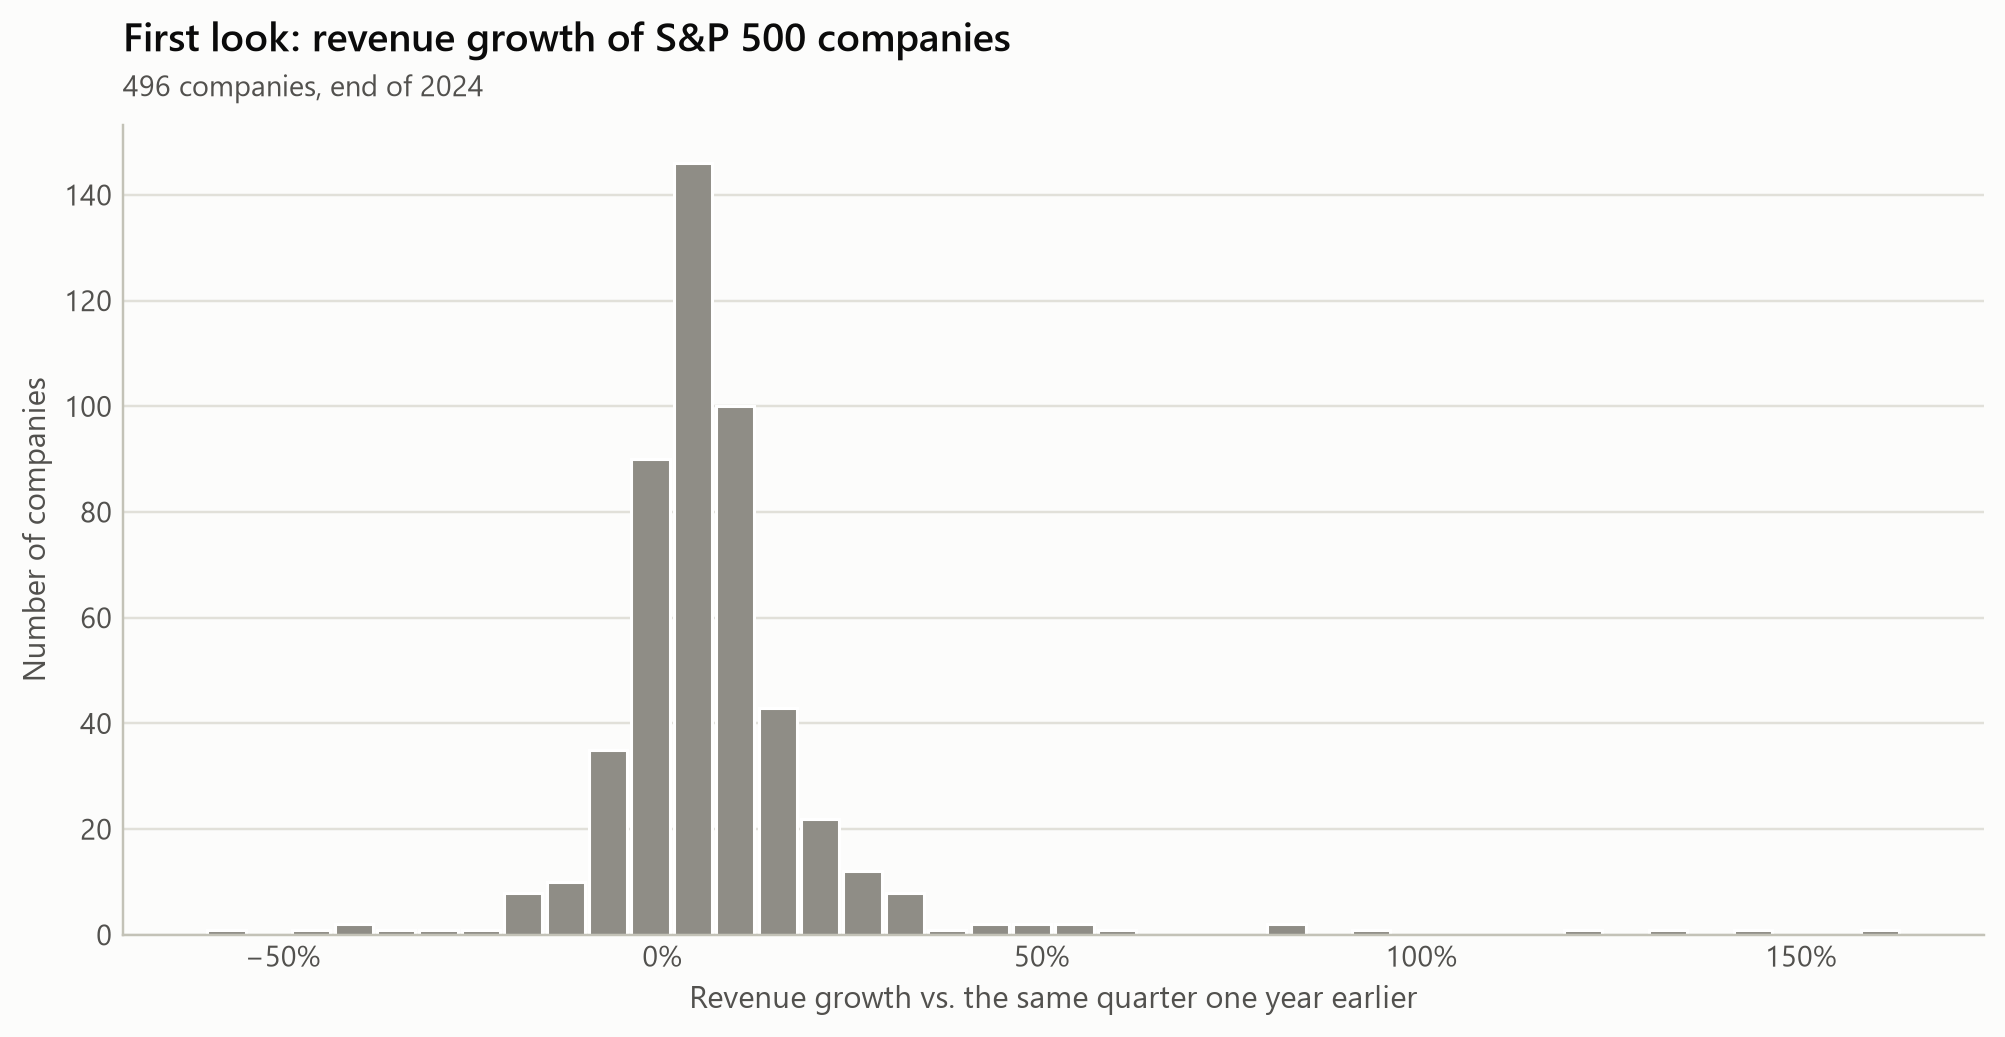

In [53]:
# Step 3: Histogram of revenue growth 40 bins

def draw_growth_histogram(ax: plt.Axes) -> None:
    """Draws the histogram of revenue growth for all 496 companies into the given axes.

    The histogram uses 40 bins over the whole range from about -60 % to +163 %.
    The bars are grey because this figure shows all companies together and no
    group, and the blue and orange are reserved for Technology and the other
    sectors. Each bar is drawn at 90 % of its bin width, so a small gap of
    background separates neighbouring bars without a dark outline. A white
    outline was tried first, but it covered most of the very short bars that
    hold only one company and made them look lighter than the others. The
    x-axis shows the growth in percent, the y-axis the number of companies in
    each bin.

    The function only draws the bars, the axis labels and the grid. Title,
    subtitle and reference lines (median, mean) are added by the cell that
    calls it, so the same histogram can be used for the first look in Step 3
    and for Figure 1 in Step 4.

    Args:
        ax: The matplotlib axes to draw into. It reads the column
            revenue_growth_pct from the cleaned DataFrame df.

    Returns:
        None. The axes is changed in place.
    """
    ax.hist(df["revenue_growth_pct"], bins=40, color=COLOR_NEUTRAL, rwidth=0.9)
    ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.set_xlabel("Revenue growth vs. the same quarter one year earlier")
    ax.set_ylabel("Number of companies")
    style_axes(ax, "y")


# First look, without any reference lines
fig, ax = plt.subplots(figsize=(9, 4.6), layout="constrained")
draw_growth_histogram(ax)
add_title(ax, "First look: revenue growth of S&P 500 companies", f"{len(df)} companies, end of 2024")
plt.show()

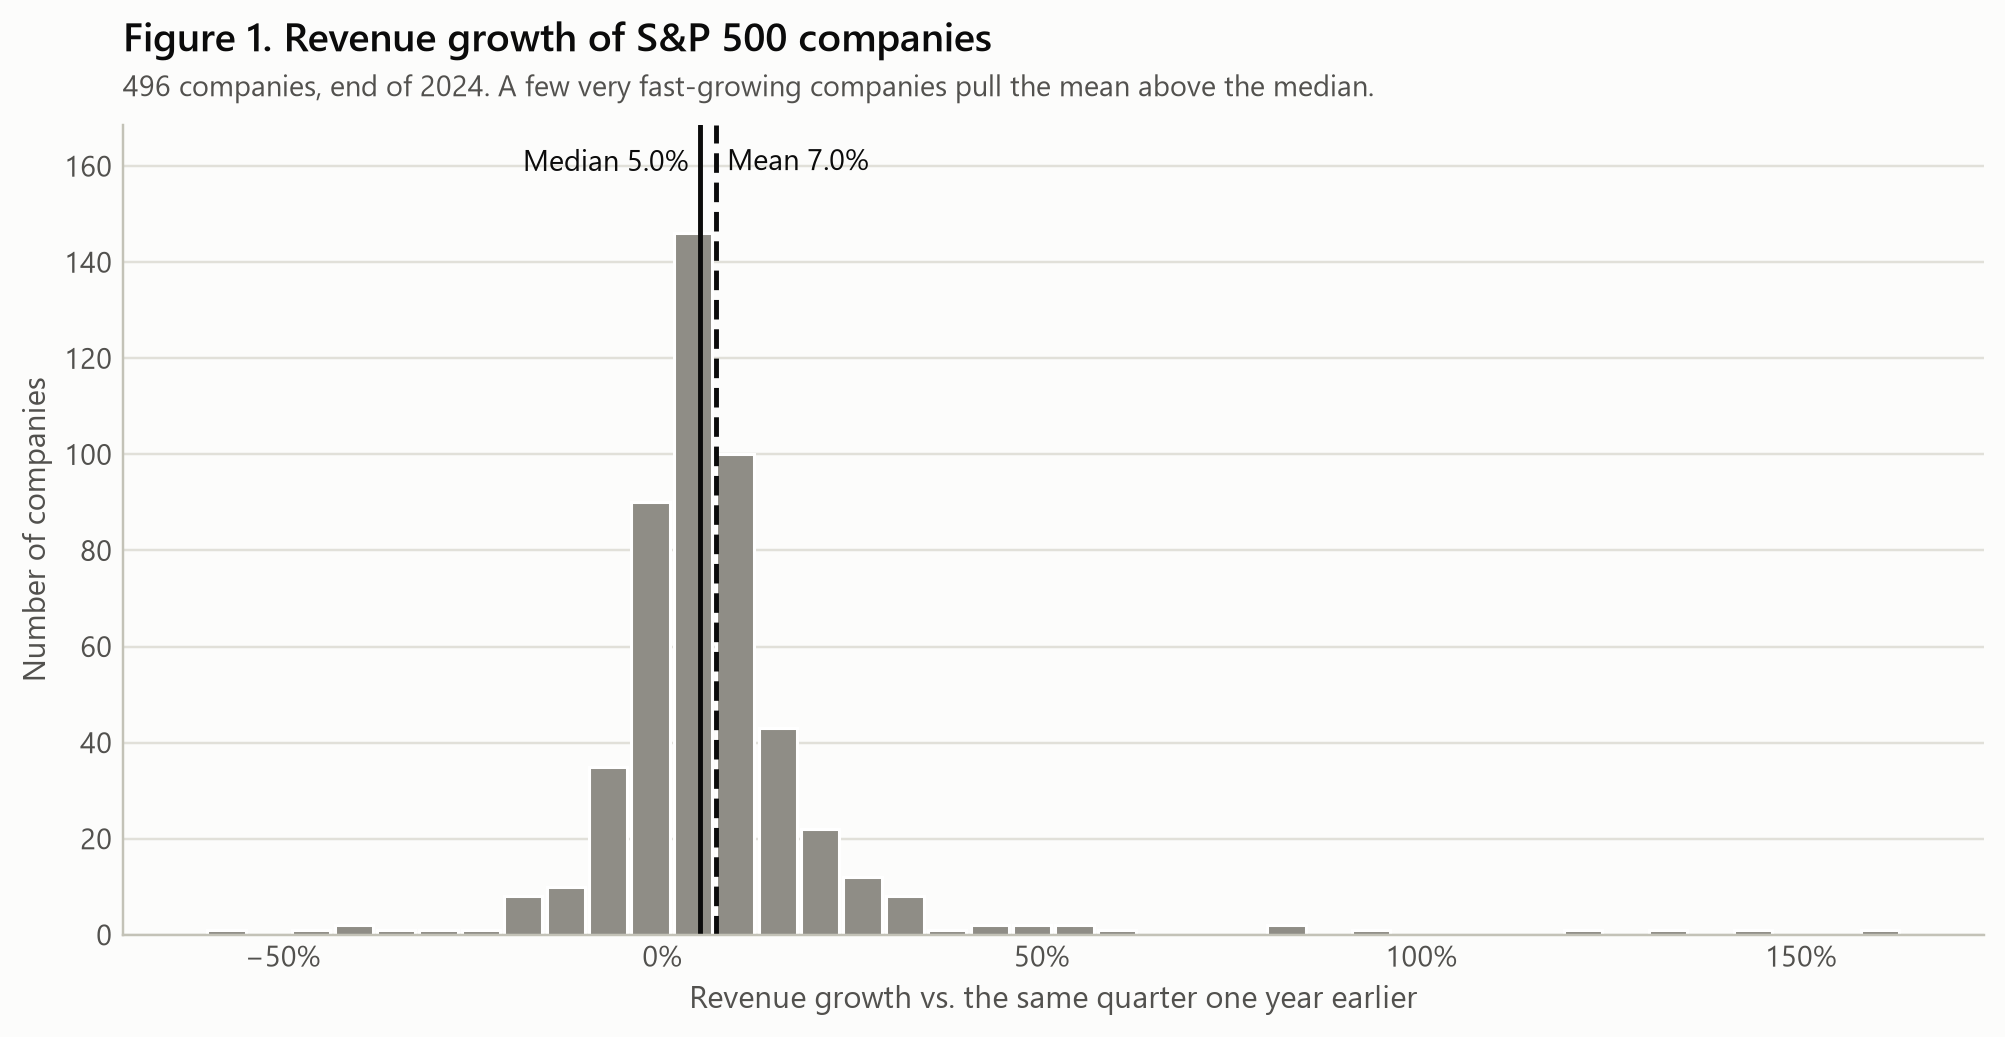

In [54]:
# Step 4: Figure 1, the same histogram with the median (solid line) and the mean (dashed line)
fig, ax = plt.subplots(figsize=(9, 4.6), layout="constrained")
draw_growth_histogram(ax)

# Some extra room above the highest bar for the two labels
top = ax.get_ylim()[1] * 1.1
ax.set_ylim(0, top)

ax.axvline(growth_median, color=INK, linewidth=1.6)
ax.axvline(growth_mean, color=INK, linewidth=1.6, linestyle=(0, (4, 2)))

# Label left of the median line and right of the mean line, so the two labels do not overlap
ax.text(growth_median - 1.5, top * 0.97, f"Median {growth_median:.1f}%", ha="right", va="top", fontsize=9.5, color=INK)
ax.text(growth_mean + 1.5, top * 0.97, f"Mean {growth_mean:.1f}%", ha="left", va="top", fontsize=9.5, color=INK)

add_title(
    ax,
    "Figure 1. Revenue growth of S&P 500 companies",
    f"{len(df)} companies, end of 2024. A few very fast-growing companies pull the mean above the median.",
)
plt.show()

#### Observation

**Figure 1**: Most companies are close together with -10% and +30%, with the highest bar just above 0%.
We see a few companies that lie far outside, down to -60% and upt to +160% (also in 3.4). The bars are hard to see, but they make the x-axis wide and pull the mean (the dashed line) above the median. In this plot the middle looks almost like a classic bell curve, but the skewness of 3.82 indicates that it is not normally distributed. A normal distribution has a skewness of 0, my plot has a long tail to the right!

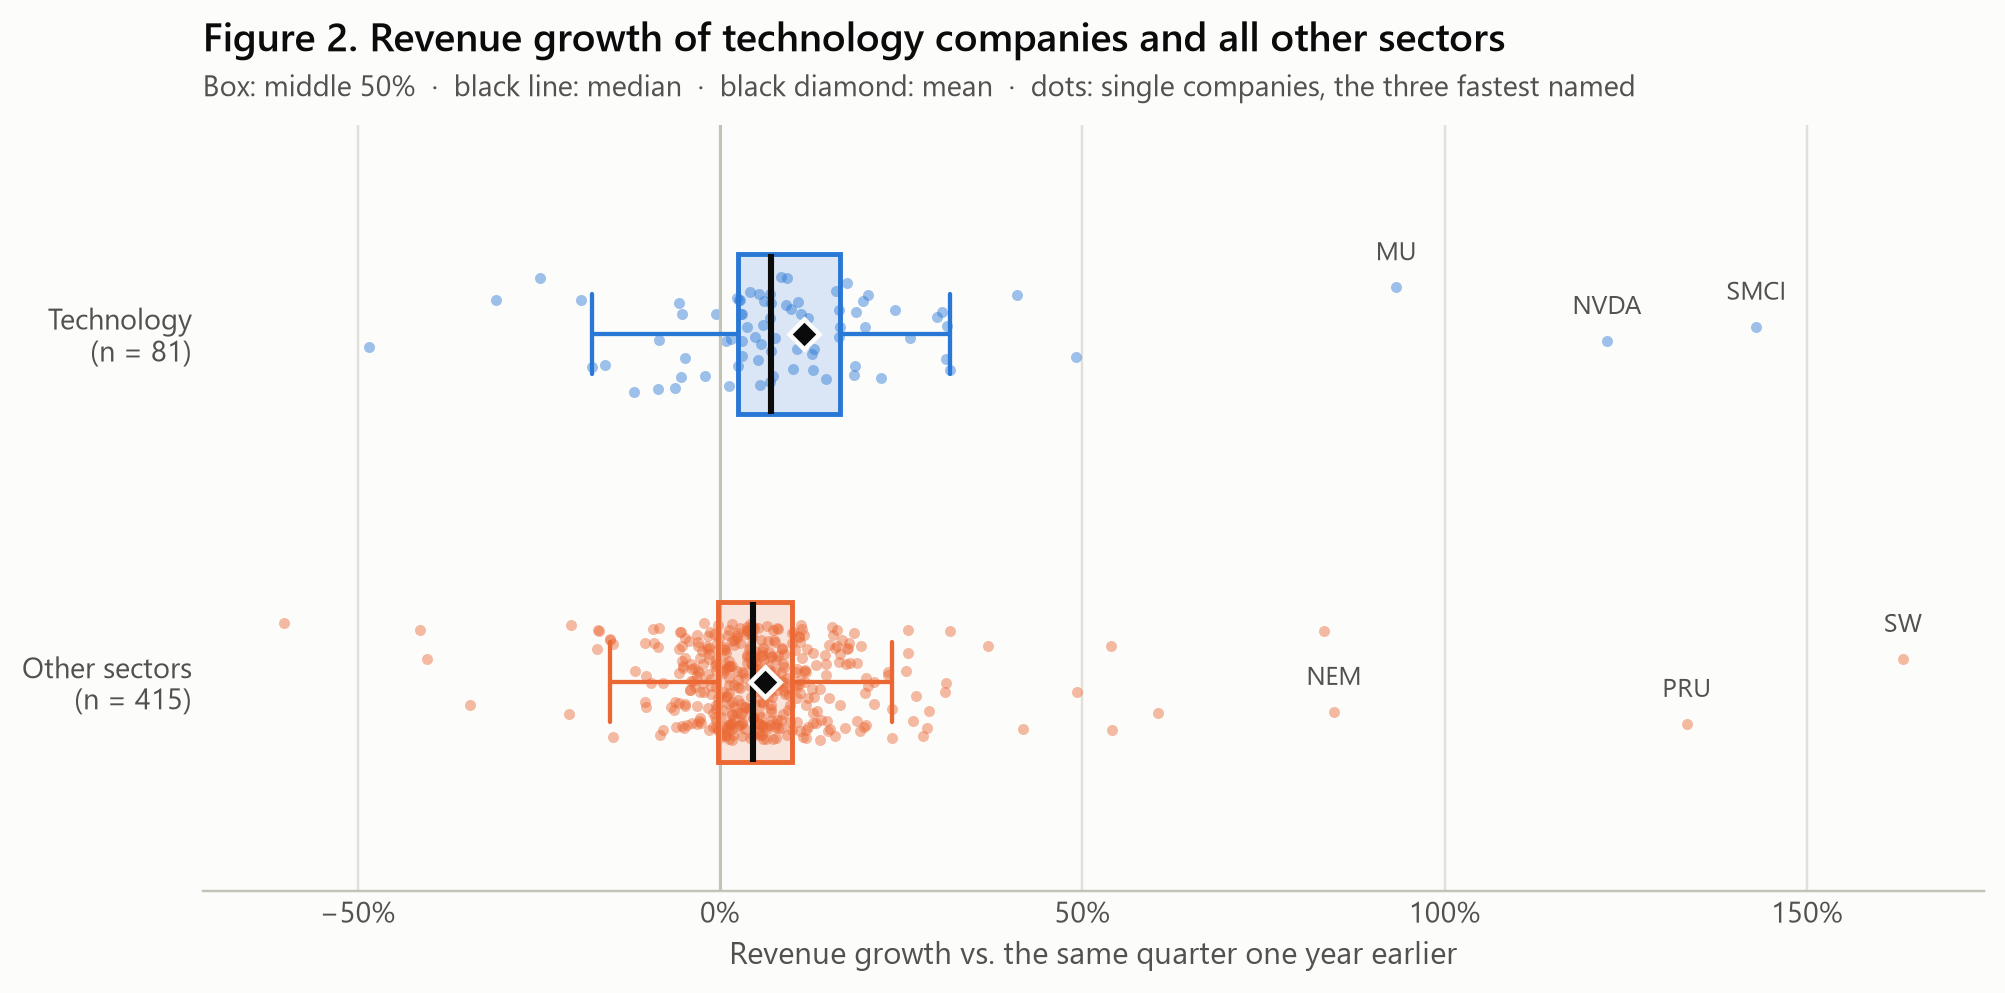

In [55]:
# Figure 2: revenue growth of the two groups as box plots, with every single company as a dot.
# The dots show what the box hides: how many companies there are and how far the few outliers lie.

# The vertical jitter of the dots uses its own random generator. Like this the global seed for the
# bootstrap in 7.4 stays untouched, and the bootstrap results do not change because of this plot.
rng_jitter = np.random.default_rng(SEED)

group_order = ["Technology", "Other sectors"]
group_position = {"Technology": 1, "Other sectors": 0}

fig, ax = plt.subplots(figsize=(9, 4.4), layout="constrained")
ax.axvline(0, color=AXIS, linewidth=1)  # 0 % growth as reference

for group_name in group_order:
    values = df.loc[df["group"] == group_name, "revenue_growth_pct"]
    color = GROUP_COLORS[group_name]
    y = group_position[group_name]

    # Box: light fill in the group color, median as a black line, mean as a black diamond
    ax.boxplot(
        values,
        positions=[y],
        orientation="horizontal",
        widths=0.46,
        patch_artist=True,
        showfliers=False,  # the outliers are already visible as dots
        showmeans=True,
        boxprops={"facecolor": matplotlib.colors.to_rgba(color, 0.16), "edgecolor": color, "linewidth": 1.6},
        whiskerprops={"color": color, "linewidth": 1.4},
        capprops={"color": color, "linewidth": 1.4},
        medianprops={"color": INK, "linewidth": 2},
        meanprops={"marker": "D", "markerfacecolor": INK, "markeredgecolor": SURFACE, "markeredgewidth": 1.5, "markersize": 7},
    )

    # One dot per company, spread a little up and down so the dots do not hide each other
    jitter = rng_jitter.uniform(-0.17, 0.17, size=len(values))
    ax.scatter(values, y + jitter, s=13, color=color, alpha=0.45, linewidths=0, zorder=1)

    # Name the three fastest-growing companies of each group with their ticker (see the outlier check below)
    for index, value in values.nlargest(3).items():
        dot_y = y + jitter[values.index.get_loc(index)]
        ax.annotate(
            df.loc[index, "Symbol"],
            xy=(value, dot_y),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8.5,
            color=INK_SECONDARY,
        )

ax.set_yticks(
    [group_position[name] for name in group_order],
    [f"{name}\n(n = {(df['group'] == name).sum()})" for name in group_order],
)
ax.set_ylim(-0.6, 1.6)
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set_xlabel("Revenue growth vs. the same quarter one year earlier")
style_axes(ax, "x")
ax.spines["left"].set_visible(False)
add_title(
    ax,
    "Figure 2. Revenue growth of technology companies and all other sectors",
    "Box: middle 50%  ·  black line: median  ·  black diamond: mean  ·  dots: single companies, the three fastest named",
)
plt.show()

#### Observation

**Figure 2**: The tech boxplot is further right and wider. The middle half of the technology comoanies grew between 2.5% and 16.6% (numbers from 5.3) compared to other sectors which grew between -0.2% and 9.9% (numbers from 5.3).
But the boxes overlap a lot, so there are also many technology companies that grew slower than companies of other sectors. There seems to be some outliers in both groups.

In [56]:
# Quick Check for the outliers:
df[df["group"] == "Technology"].nlargest(5, "revenue_growth_pct")[["Symbol", "Shortname", "revenue_growth_pct"]]


,Symbol,Shortname,revenue_growth_pct
384,SMCI,"Super Micro Computer, Inc.",143.0
1,NVDA,NVIDIA Corporation,122.4
96,MU,"Micron Technology, Inc.",93.3
385,STX,Seagate Technology Holdings PLC,49.1
50,INTU,Intuit Inc.,41.0


In [57]:
# The 5 companies from the other sectors with the highest revenue growth
df[df["group"] == "Other sectors"].nlargest(5, "revenue_growth_pct")[["Symbol", "Shortname", "revenue_growth_pct"]]


,Symbol,Shortname,revenue_growth_pct
307,SW,Smurfit WestRock plc,163.2
223,PRU,"Prudential Financial, Inc.",133.4
215,NEM,Newmont Corporation,84.7
341,CINF,Cincinnati Financial Corporatio,83.3
216,DFS,Discover Financial Services,60.5


#### Observation:

**Outliers:** 
- Three tech companies grew a lot faster than all other tech companies, Super Micro Computer Inc. (+143 %), NVIDIA (+122 %) and Micron Technology (+93 %). Those are the three points on the right in Figure 2, and they pull the tech mean up
- in other sectors I also have very high values, like Smurfit WestRock (+163 %) and Prudential (+133 %) but with a set of 415 companies they move the mean less.


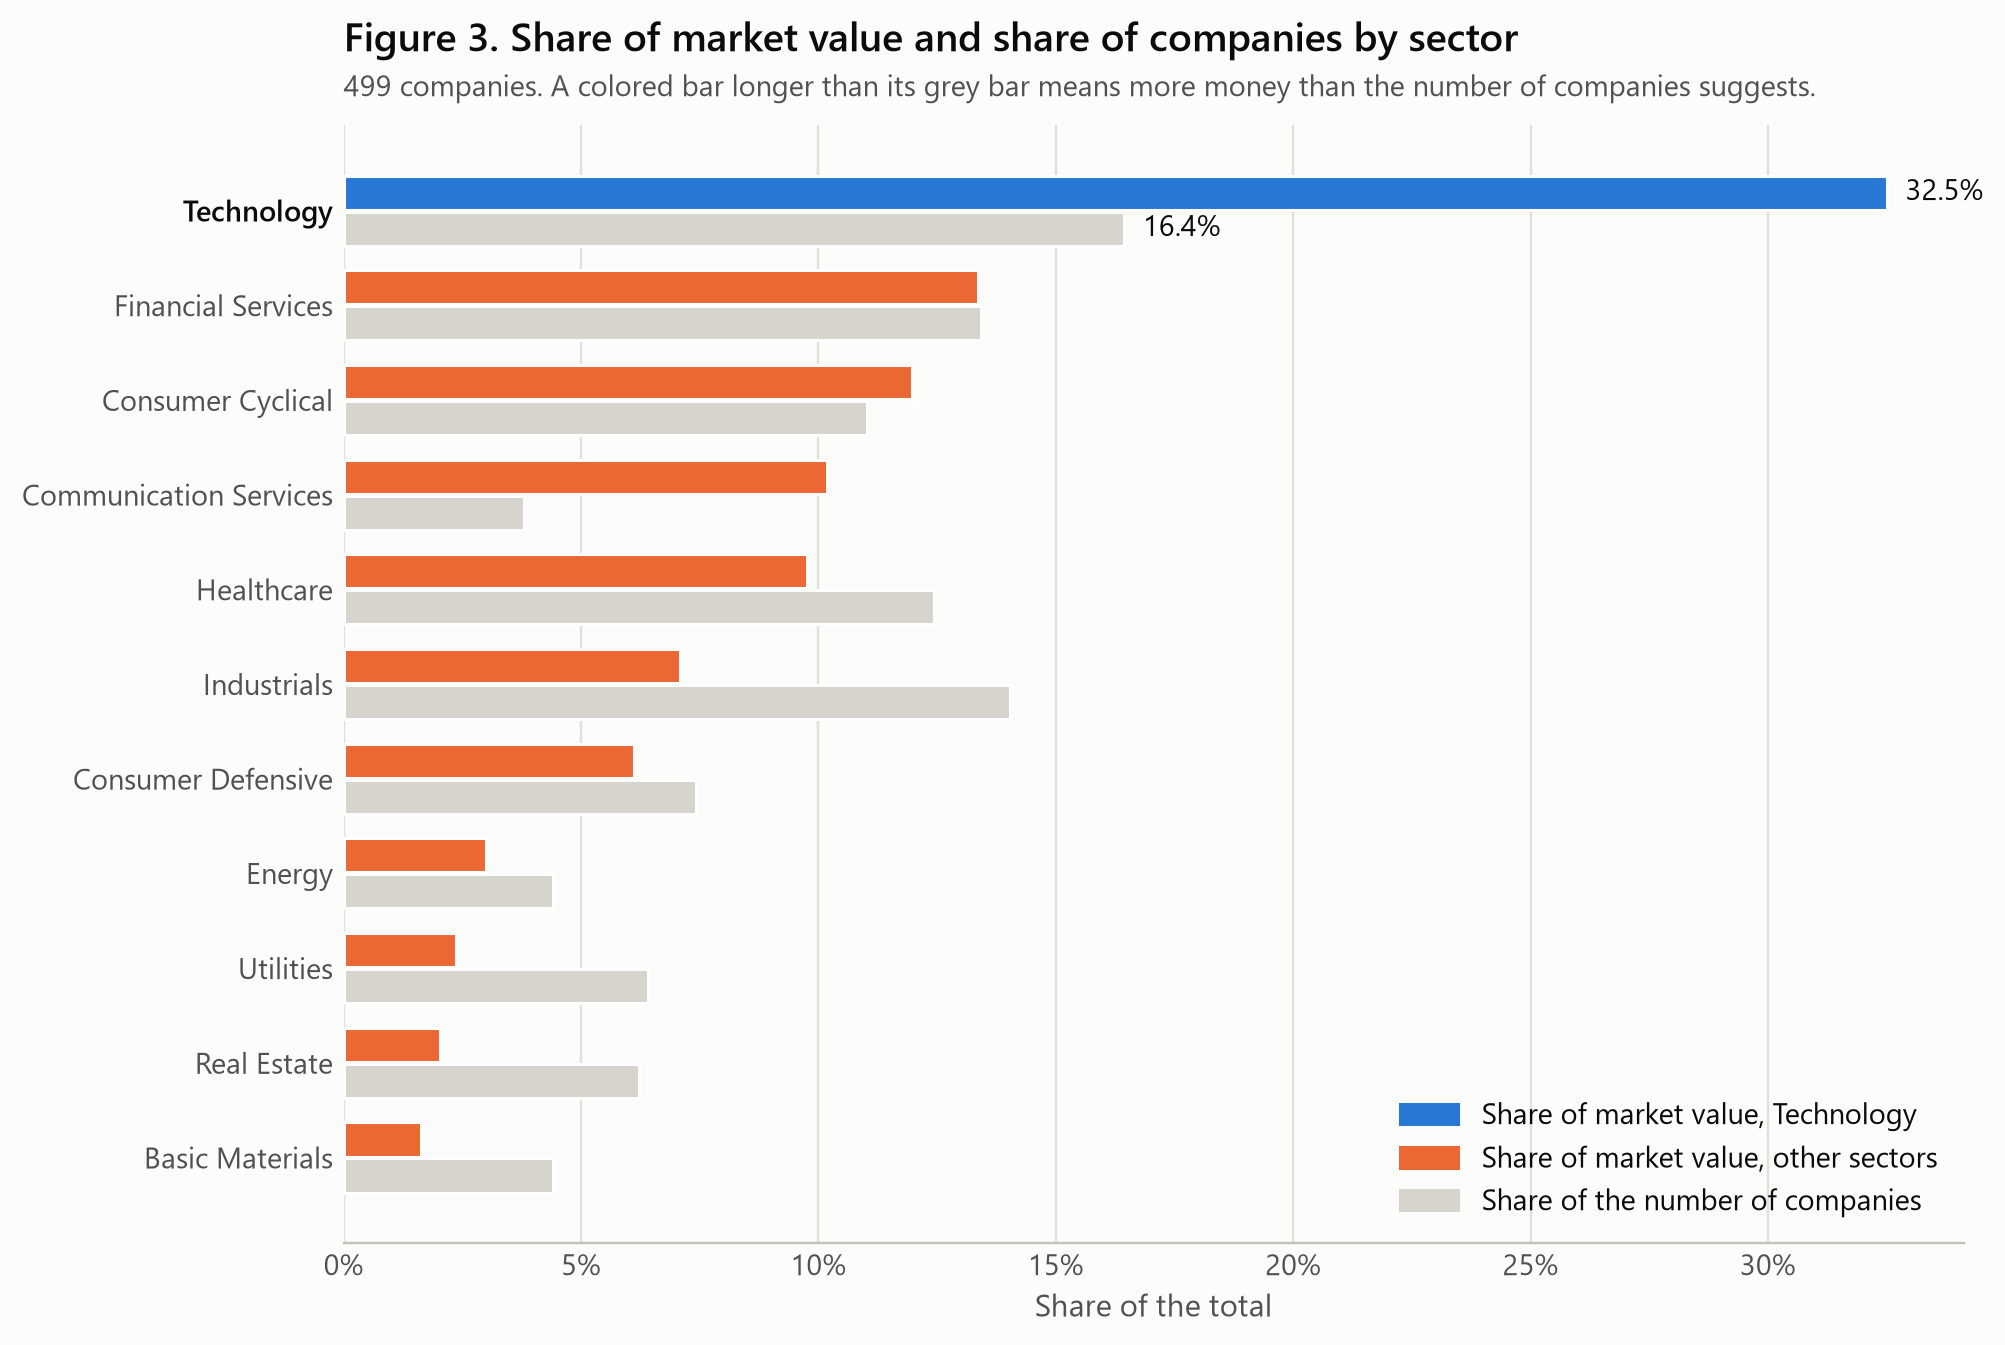

In [58]:
# Figure 3: two bars for each sector
# colored bar (top): the sectors share of the total market value so this shows the share of the money in the total.
# grey bar (below): the sectors share of the number of companies (companies in the sector / all the 499 companies)

# Rank the sectors by market value share, the biggest ends up on top
ranked = concentration.sort_values("share_of_market_value_pct")
colors = [COLOR_TECH if sector == "Technology" else COLOR_OTHER for sector in ranked.index]
position = np.arange(len(ranked))

fig, ax = plt.subplots(figsize=(9, 6), layout="constrained")
ax.barh(position + 0.19, ranked["share_of_market_value_pct"], height=0.36, color=colors)
ax.barh(position - 0.19, ranked["share_of_companies_pct"], height=0.36, color=COLOR_NEUTRAL_LIGHT)

# Write the two values only for Technology, the sector the question is about. All other values are in the table of 5.2.
tech_row = list(ranked.index).index("Technology")
for offset, column in [(0.19, "share_of_market_value_pct"), (-0.19, "share_of_companies_pct")]:
    value = ranked.loc["Technology", column]
    ax.text(value + 0.4, tech_row + offset, f"{value:.1f}%", va="center", ha="left", fontsize=9.5, color=INK)

ax.set_yticks(position, ranked.index)
for label in ax.get_yticklabels():
    if label.get_text() == "Technology":
        label.set_fontweight("semibold")
        label.set_color(INK)

ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set_xlabel("Share of the total")
style_axes(ax, "x")
ax.spines["left"].set_visible(False)
ax.legend(
    handles=[
        Patch(color=COLOR_TECH, label="Share of market value, Technology"),
        Patch(color=COLOR_OTHER, label="Share of market value, other sectors"),
        Patch(color=COLOR_NEUTRAL_LIGHT, label="Share of the number of companies"),
    ],
    loc="lower right",
)
add_title(
    ax,
    "Figure 3. Share of market value and share of companies by sector",
    f"{len(companies)} companies. A colored bar longer than its grey bar means more money than the number of companies suggests.",
)
plt.show()

**Figure 3:** This shows something very clearly: if the color bar is longer than the gray bar, the sector gets more money than its number of companies would suggest. 
Technology has twice as much market value as its percentage of companies
Communication Services (with Alphabet and Meta) even more, if we would consider them as tech companies the picture would even look more skewed. 
Most other sectors are the other way around, most clearly Industrials, Utilities, Real Estate and Basic Materials.

#### Observation: What the plots tell us
- 1. Histogram: The shape of the growth: most companies are close together a few stretch the plot far out. This tells me that it is also necessary to use the median for further analysis.
- 2. Box Plot: This shows the median and the spread, also the overlap between tech and other sectors, this this clearly shows the distribution of the revenue growth of each sector to be further analysed.
- 3. Bar Chart: This clearly shows the different distribution of shares between the actual market value by the sectors compared to the number of companies in % contributing to the total, shows the importance of the resaearch question (but nothing about the growth)

Figure 2 supports my question best. It is the only figure that shows both groups and it shows what the means alone hide: the groups overlap a lot, and a few tech companies lie far right and pull the tech mean up.

---

## 7. Hypothesis Testing

### 7.1 Hypotheses

From the analysis plan at the beginning I compare 2 groups
- H0: μ_Tech = μ_Other. Technology companies and the other companies have the same mean revenue growth.
- H1: μ_Tech ≠ μ_Other. The means are different (two-sided).
- α = 0.05: I reject H0 if p ≤ 0.05.

The p-value is the probability of a difference at least as big as the observed one if H0 were true.

### 7.2 Which test and why
My Research question compares the means of two independent groups, so I use a two-sample t-test. While researching this scenario I came across Delacre et al. (in the summary) This t-test has two versions.

- **Students t-test** (equal_var=True, the default) assumes that both groups have the same variance and takes the two variances into one.
- **Welchs t-test** (equal_var=False) does not assume this. It uses the variance of each group on its own.

In 5.3 the two groups looked very different in size and in spread. The two steps below show how different.


In [59]:
# Step 1: Revenue growth of each group, number of companies and variance
tech = df[df["group"] == "Technology"]["revenue_growth_pct"]
other = df[df["group"] == "Other sectors"]["revenue_growth_pct"]

print("Technology:", len(tech), "companies Other sectors:", len(other), "companies")
print("Technology variance:", round(tech.var(), 2))
print("Other sectors variance:", round(other.var(), 2))

Technology: 81 companies Other sectors: 415 companies
Technology variance: 691.04
Other sectors variance: 252.21


In [60]:
# Step 2: How many times bigger is the standard deviation/ variance of the tech group?
print("Ratio of standard deviations:", round(tech.std() / other.std(), 2))
print("Ratio of variances:", round(tech.var() / other.var(), 2))

Ratio of standard deviations: 1.66
Ratio of variances: 2.74


#### Observation

The technology group is more than 5 times smaller in number (81 vs 415 df set), but its standard deviation (and variance) is 1.66 times (2.74 times) as large as the one from the other sectors.
This means that if we would use the regular students t-test the variance of both groups combined would mostly be influenced by the less noisy group of the other sectors group, so the test underestimates how uncertain the tech mean actually is!
This would result in a too high t-value and it would find a difference when there is none (DelacSre et al.) 

Here Welchs t-test shines as it does not have this problem, and Delacre et al. (2017) recommend it as the default when the groups are of very different size as is the case here.


#### Assumptions:

- Independent observation: one row per company. Companies are in the same sector (tech) and in the same market (mainly US/ World economy) so this is only partly true and would need further analysis but general market development make them less independent.
- Roughly Normal Sampling Distribution of the difference in means: THe Datasets are both skewed,but the groups are large I will bootstrap this to check it!

### 7.3 Welch t-test

NOTE: In the course we computed the observed difference and got the p-value from a simulation, here I only use Welch t-test from scipy, it gives us the p-value and the confidence interval directly.

In [61]:
# Step 1: Observed difference in means (obs_diff like in the course)
obs_diff = tech.mean() - other.mean()
print(round(obs_diff, 2))

5.43


In [62]:
# Step 2 (new): Welch t-test: equal_var=False means each one of the groups keep their own variance

welch = stats.ttest_ind(tech, other, equal_var=False)
print(welch)
t_stat, p_value = welch


print("t-statistic:", round(t_stat, 3))
print("p-value:", round(p_value, 4))

TtestResult(statistic=np.float64(1.7968737608504466), pvalue=np.float64(0.07564745108074532), df=np.float64(91.71374754927731))
t-statistic: 1.797
p-value: 0.0756


In [63]:
# Step 3: 95% confidence interval for the difference in means

ci = welch.confidence_interval(confidence_level=1 - ALPHA)
print("95% confidence interval:", round(ci.low, 2), round(ci.high, 2))

95% confidence interval: -0.57 11.44


In [64]:
# Step 4: Decision, compare the p-value with alpha
if welch.pvalue <= ALPHA:
    print("p <= 0.05: reject H0")
else:
    print("p > 0.05: fail to reject H0")

p > 0.05: fail to reject H0


#### Result

p=0.0756 > 0.05, so I fail to reject H0. Technology companies grew 5.4 points faster on average, but confidence interval from -0.57 to 11.44% points includes zero. This does not prove that there is no difference: the tech group varies too heavily for a clear answer!

### 7.4 Checks with bootstrap

I draw the 496 companies again with replacement, 10000 times and keep the differences in means and additionally the differences in medians each times.

In [65]:
# Step 1: Bootstrap differences in means and medians
diffs, median_diffs = [], []
for _ in range(10000):
    bootsamp = df.sample(496, replace=True)
    tech_boot = bootsamp[bootsamp["group"] == "Technology"]["revenue_growth_pct"]
    other_boot = bootsamp[bootsamp["group"] == "Other sectors"]["revenue_growth_pct"]
    diffs.append(tech_boot.mean() - other_boot.mean())
    median_diffs.append(tech_boot.median() - other_boot.median())

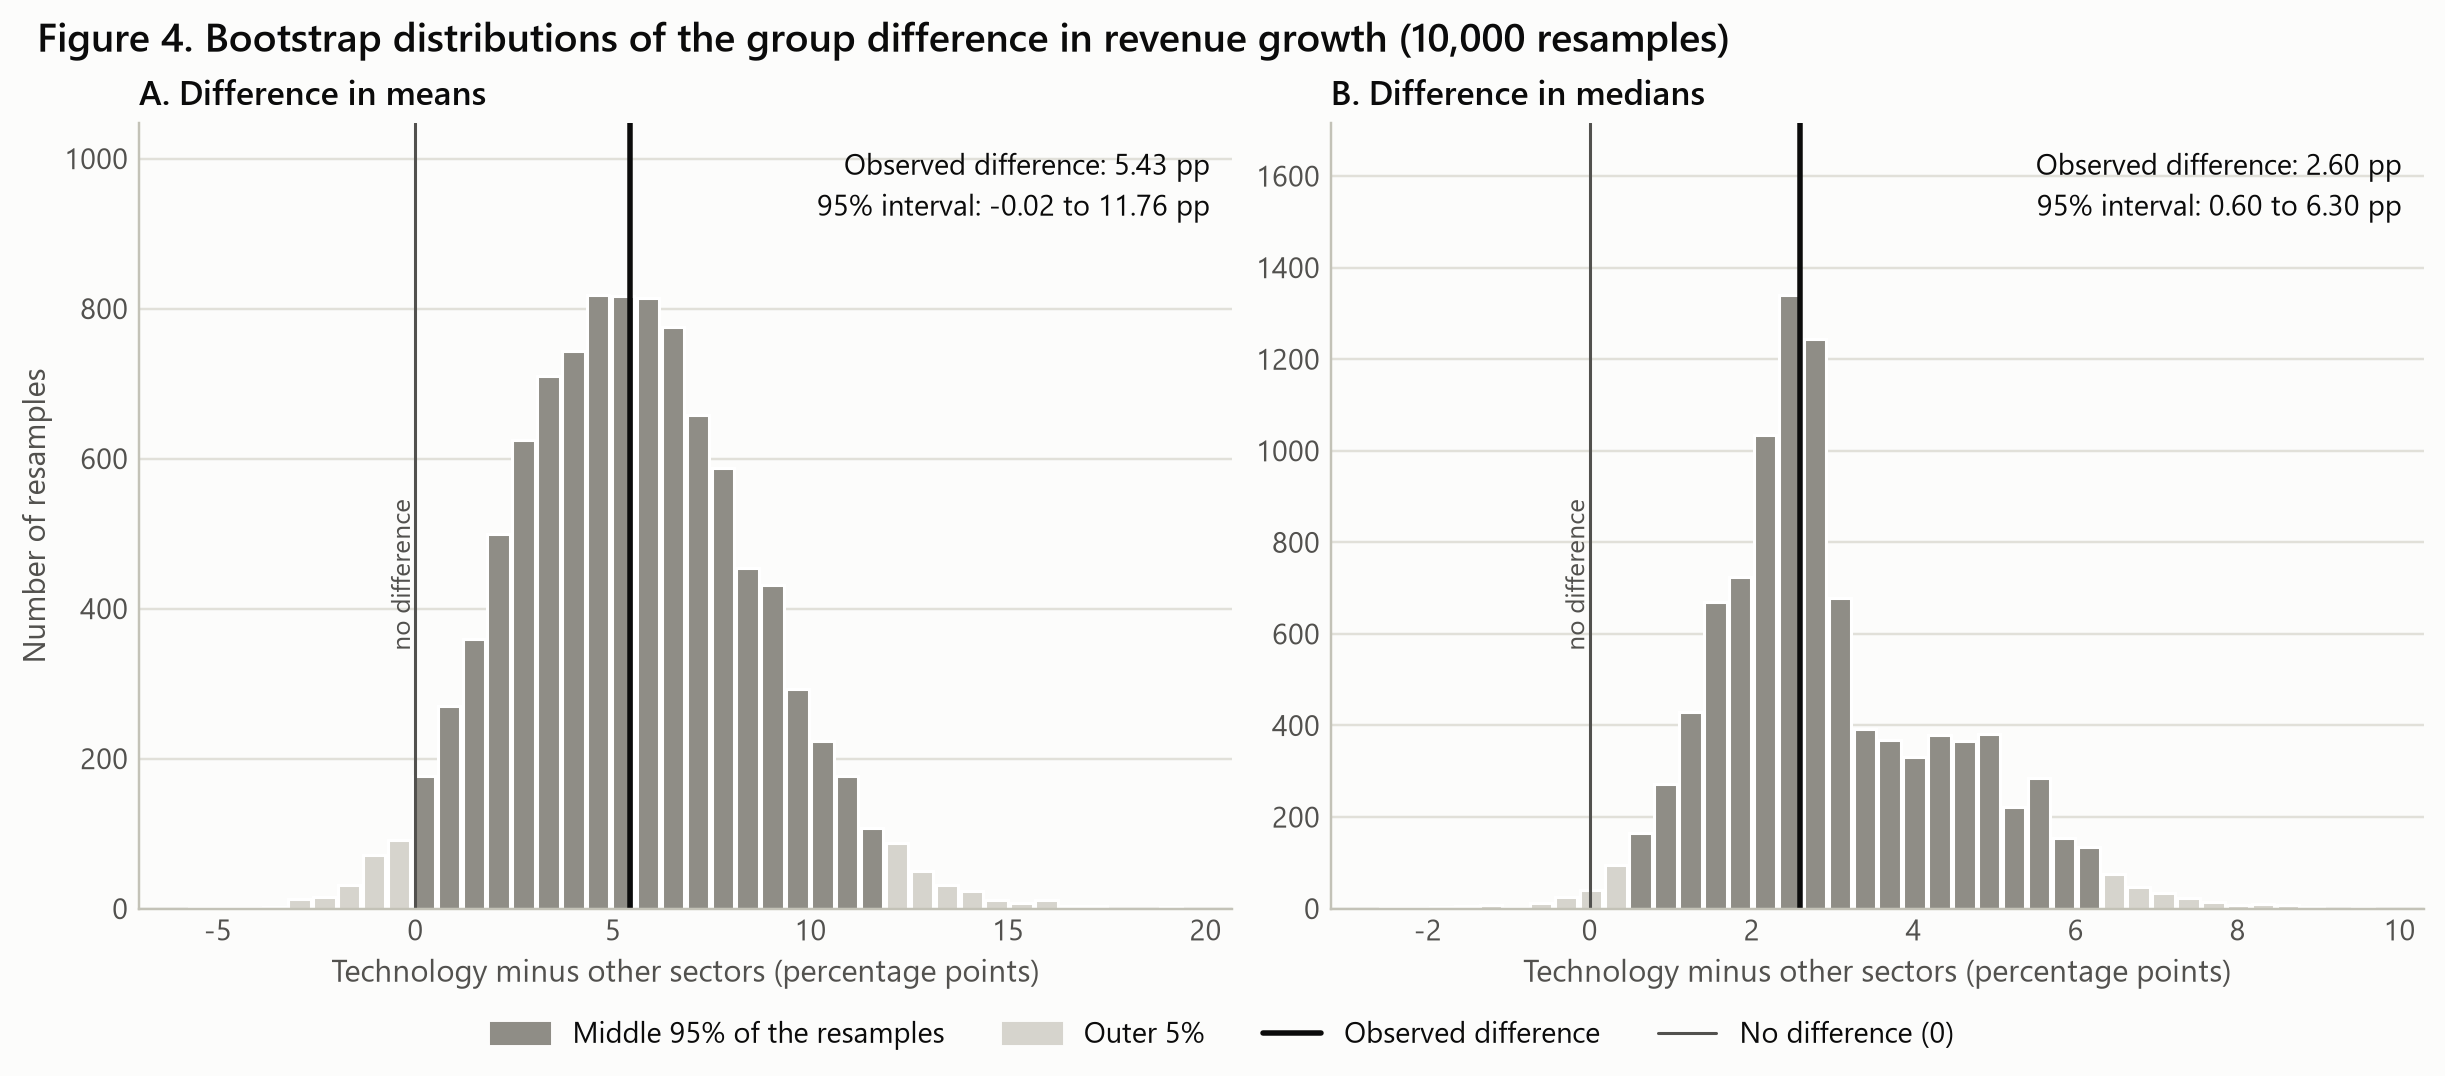

In [66]:
# Figure 4: the 10000 bootstrap differences, A for the means and B for the medians.
# Dark bars are the middle 95 % of the resamples (the 95 % bootstrap interval), light bars the outer 5 %.
# The black line is the observed difference in the real data, the thin grey line marks 0 (no difference).
# If the dark bars reach over the grey line, the interval includes zero.

panels = [
    ("A. Difference in means", np.array(diffs), tech.mean() - other.mean()),
    ("B. Difference in medians", np.array(median_diffs), tech.median() - other.median()),
]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), layout="constrained")
for ax, (panel_title, values, observed) in zip(axes, panels):
    low, high = np.percentile(values, [2.5, 97.5])

    # Histogram by hand, so each bar can get its own color: dark inside the interval, light outside.
    # Bars at 90 % of the bin width leave a small gap, like in Figure 1.
    counts, edges = np.histogram(values, bins=40)
    centers = (edges[:-1] + edges[1:]) / 2
    inside = (centers >= low) & (centers <= high)
    ax.bar(
        centers,
        counts,
        width=np.diff(edges) * 0.9,
        color=np.where(inside, COLOR_NEUTRAL, COLOR_NEUTRAL_LIGHT),
    )

    top = counts.max()
    ax.axvline(0, color=INK_SECONDARY, linewidth=1)
    ax.axvline(observed, color=INK, linewidth=1.8)
    ax.text(0, top * 0.55, "no difference ", rotation=90, ha="right", va="center", fontsize=8.5, color=INK_SECONDARY)

    # The two numbers the decision is based on, top right where the histogram leaves space
    ax.text(
        0.98,
        0.97,
        f"Observed difference: {observed:.2f} pp\n95% interval: {low:.2f} to {high:.2f} pp",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=9.5,
        color=INK,
        linespacing=1.5,
    )

    ax.set_ylim(0, top * 1.28)
    ax.set_title(panel_title, loc="left", fontsize=11)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:g}"))
    ax.set_xlabel("Technology minus other sectors (percentage points)")
    style_axes(ax, "y")

axes[0].set_ylabel("Number of resamples")
fig.suptitle(
    "Figure 4. Bootstrap distributions of the group difference in revenue growth (10,000 resamples)",
    x=0.01,
    ha="left",
    fontsize=13,
    fontweight="semibold",
)
fig.legend(
    handles=[
        Patch(color=COLOR_NEUTRAL, label="Middle 95% of the resamples"),
        Patch(color=COLOR_NEUTRAL_LIGHT, label="Outer 5%"),
        Line2D([], [], color=INK, linewidth=1.8, label="Observed difference"),
        Line2D([], [], color=INK_SECONDARY, linewidth=1, label="No difference (0)"),
    ],
    loc="outside lower center",
    ncols=4,
)
plt.show()

In [67]:
# Step 2: Skewness of the bootstrap differences, as in 5.1 (0 = symmetric, like a normal distribution)
print(round(pd.Series(diffs).skew(), 2))

0.25


In [68]:
# Step 3: 95 % bootstrap interval for the difference in means (the middle 95 % of the differences)
print(np.percentile(diffs, [2.5, 97.5]).round(2))

[-0.02 11.76]


In [69]:
# Step 4: The same for the medians
print("Difference in medians:", round(tech.median() - other.median(), 2))
print("95 % bootstrap interval:", np.percentile(median_diffs, [2.5, 97.5]).round(2))

Difference in medians: 2.6
95 % bootstrap interval: [0.6 6.3]


#### Result
Figure 4A is almost symmetric (skewness 0.25), so the assumption of a roughly normal sampling distribution holds.
The bootstrap for the means gives the same decision as Welchs t-test: the interval −0.02 to 11.76 just includes zero, in Figure 4A the dark bars just reach over the grey zero line.
The median interval (0.6 to 6.3) does not include zero, in Figure 4B all dark bars lie right of the zero line: the typical technology company grew a bit faster, and the bigger gap in the means comes from a few extremely fast-growing companies. I keep the planned test of the means, because switching to the median now would mean picking the test by its result.

---

## 8. Summary

- I used a dataset of 502 rows and 16 columns, one per listed share of the S&P 500 at the end of 2024, and checked the 499 companies behind them to see how concentrated the index and therfore any S&P500 ETF is and if technology companies grew faster than the rest.
- The index is very concentrated: Technology is 32.5% of the market value but only 16.4% of the companies, so average contribution per company towards the market value of the whole index is overrepresented.
- The ten biggest companies hold 38.9% of the whole index.
- Surprisingly the higher mean revenue growth of technology companies (11.6% vs 6.2%) was not statistically significant (Welch t-test = 1.80, p = 0.076), because a few companies like NVIDIA or SUper Micro Computer move the mean up and make the group spread strongly, so we see large variance inside the group.
- The main challenges were data quality and data cleaning problems: Duplicates in share classes, missing EBITDA, and a price dataset that was 2/3 empty. So in this snapshow the bigh weight of tech in the index is not backed by a clear growth lead of the whole sector